# 06 · La elección del campeón

Tres preguntas antes de elegir (decisión 006):

1. **¿La ventaja sobre Lending Club es real o es ruido?** Intervalos de confianza por bootstrap.
2. **¿Las PD están bien calibradas?** Una PD de 10% debería tener ~10% de malos.
3. **¿Cuánto dinero gana la cartera** aprobando con cada modelo?

Todo sobre 2015 (fuera de tiempo).

In [1]:
import sys, json, warnings
sys.path.insert(0, "../src")
warnings.filterwarnings("ignore")
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.optimize import brentq
from credit_lab.poblacion import cargar_poblacion
from credit_lab.metricas import bootstrap_auc, tabla_calibracion, resumen, discriminacion
from credit_lab.negocio import utilidad_prestamo, utilidad_por_corte

pd.set_option("display.float_format", "{:,.4f}".format)
TINTA, TINTA_2, GRILLA = "#0b0b0b", "#52514e", "#e5e4df"
plt.rcParams.update({
    "figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False,
    "axes.edgecolor": GRILLA, "axes.labelcolor": TINTA_2, "xtick.color": TINTA_2,
    "ytick.color": TINTA_2, "axes.grid": True, "grid.color": GRILLA, "grid.linewidth": 0.6,
    "axes.titlecolor": TINTA, "axes.titleweight": "bold", "axes.titlelocation": "left",
})
NOMBRES = {"logistica": "Logística", "int_rate": "int_rate (Lending Club)", "lgbm": "LightGBM",
           "xgb": "XGBoost", "torch": "Red PyTorch", "mlp": "Red scikit-learn", "rf": "Random Forest"}
COLOR = {"logistica": "#2a78d6", "int_rate": "#eb6834", "lgbm": "#1baf7a", "xgb": "#eda100",
         "torch": "#e87ba4", "mlp": "#008300", "rf": "#6250d6"}
MODELOS = ["lgbm", "xgb", "torch", "mlp", "rf", "logistica"]

pred = pd.read_parquet("../modelos/predicciones_oot.parquet")
oot = cargar_poblacion().loc[pred.index]
assert (oot["malo"].values == pred["malo"].values).all()
y = pred["malo"]
scores = {m: pred[f"pd_{m}"] for m in MODELOS} | {"int_rate": pred["int_rate"]}

## 1. ¿La ventaja es significativa?

**Bootstrap pareado** (300 réplicas): en cada réplica se remuestrean los mismos préstamos para todos los modelos y se mide la diferencia de AUC contra Lending Club. Si el intervalo del 95% **no incluye el cero**, la ventaja es real.

In [2]:
boot = bootstrap_auc(y, scores, referencia="int_rate", n=300)
boot.index = [NOMBRES[i] for i in boot.index]
boot.sort_values("dif_auc", ascending=False)

,dif_auc,ic95_inf,ic95_sup,prob_no_mejora
LightGBM,0.0039,0.0016,0.0063,0.0000
XGBoost,0.0038,0.0015,0.0063,0.0000
Red PyTorch,0.0014,-0.0008,0.0038,0.1333
Red scikit-learn,-0.0013,-0.0038,0.0013,0.8400
Random Forest,-0.0076,-0.0101,-0.0050,1.0000
Logística,-0.0258,-0.0282,-0.0231,1.0000


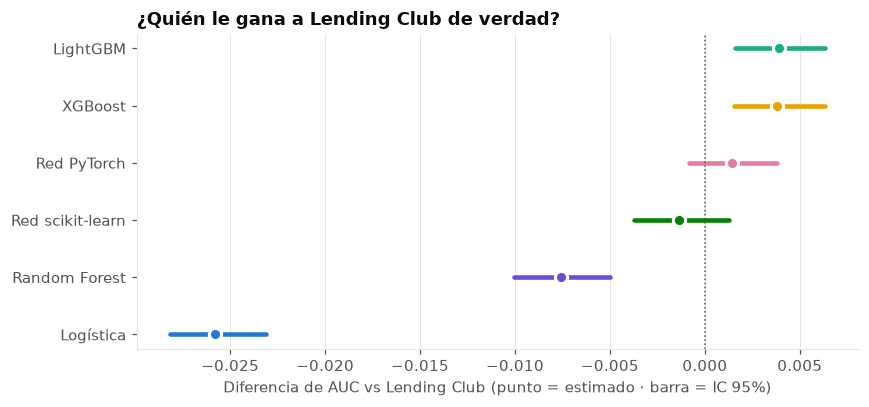

In [3]:
b = boot.sort_values("dif_auc")
fig, ax = plt.subplots(figsize=(8, 3.8))
claves = {v: k for k, v in NOMBRES.items()}
for i, (nombre, fila) in enumerate(b.iterrows()):
    color = COLOR[claves[nombre]]
    ax.plot([fila["ic95_inf"], fila["ic95_sup"]], [i, i], color=color, linewidth=3, solid_capstyle="round")
    ax.plot(fila["dif_auc"], i, "o", color=color, markersize=8, markeredgecolor="white", markeredgewidth=2)
ax.axvline(0, color=TINTA_2, linewidth=1, linestyle=":")
ax.set_yticks(range(len(b)), b.index)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Diferencia de AUC vs Lending Club (punto = estimado · barra = IC 95%)")
ax.set_title("¿Quién le gana a Lending Club de verdad?")
fig.tight_layout()

In [4]:
lgbm_vs_xgb = bootstrap_auc(y, {"lgbm": scores["lgbm"], "xgb": scores["xgb"]}, referencia="xgb", n=300)
lgbm_vs_xgb.rename(index={"lgbm": "LightGBM − XGBoost"})

,dif_auc,ic95_inf,ic95_sup,prob_no_mejora
modelo,,,,
LightGBM − XGBoost,0.0001,-0.0003,0.0005,0.3333


## 2. Calibración: ¿las PD dicen la verdad?

El AUC mide si el modelo **ordena** bien; la calibración mide si el **nivel** de la PD es correcto. Para provisiones, pricing y capital importa el nivel.

In [5]:
calib = pd.DataFrame({NOMBRES[m]: {"pd_media": pred[f"pd_{m}"].mean(), "tasa_real": y.mean(),
                                    "brier": resumen(y, pred[f"pd_{m}"])["brier"]} for m in MODELOS}).T
calib["subestimacion_pp"] = (calib["tasa_real"] - calib["pd_media"]) * 100
calib.sort_values("brier")

,pd_media,tasa_real,brier,subestimacion_pp
LightGBM,0.1313,0.1489,0.1202,1.7517
XGBoost,0.1316,0.1489,0.1202,1.7310
Red PyTorch,0.1390,0.1489,0.1205,0.9845
Red scikit-learn,0.1207,0.1489,0.1212,2.8167
Random Forest,0.1317,0.1489,0.1214,1.7207
Logística,0.1314,0.1489,0.1224,1.7508


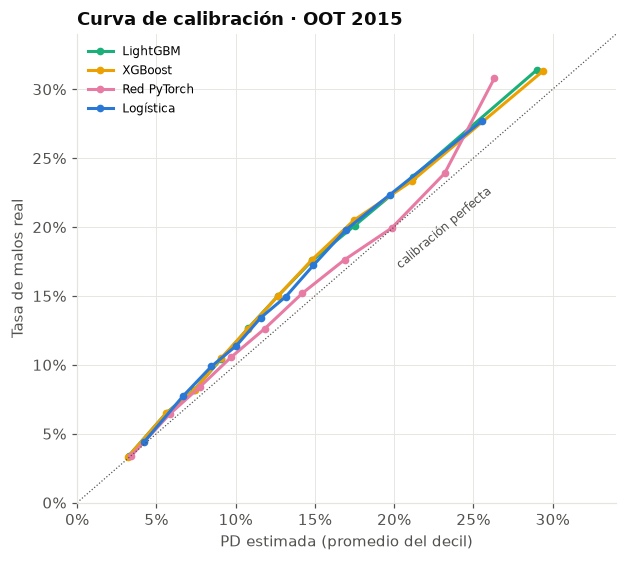

In [6]:
fig, ax = plt.subplots(figsize=(5.8, 5.2))
for m in ["lgbm", "xgb", "torch", "logistica"]:
    t = tabla_calibracion(y, pred[f"pd_{m}"])
    ax.plot(t["pd_estimada"], t["tasa_real"], color=COLOR[m], linewidth=2, marker="o", markersize=4, label=NOMBRES[m])
lim = [0, 0.34]
ax.plot(lim, lim, color=TINTA_2, linewidth=0.8, linestyle=":")
ax.text(0.2, 0.17, "calibración perfecta", rotation=40, fontsize=8, color=TINTA_2)
ax.set_xlim(lim); ax.set_ylim(lim)
ax.xaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.yaxis.set_major_formatter(lambda v, _: f"{v:.0%}")
ax.set_xlabel("PD estimada (promedio del decil)")
ax.set_ylabel("Tasa de malos real")
ax.set_title("Curva de calibración · OOT 2015")
ax.legend(frameon=False, loc="upper left", fontsize=8)
fig.tight_layout()

### ¿Se corrige con una recalibración?

La subestimación es **pareja**: ~1,7 puntos tanto en el 1er como en el 2º semestre de 2015, porque 2015 fue un año más riesgoso que 2012–2014. Eso se corrige con una **recalibración del intercepto**: se ajusta solo el nivel de la PD, sin cambiar el orden (el AUC queda igual).

Para hacerlo sin hacer trampa: se **recalibra con el 1er semestre de 2015** y se **evalúa en el 2º**, como se haría en producción con la información más reciente.

In [7]:
s1 = oot["issue_d"].dt.month.le(6).values
logit = lambda p: np.log(p / (1 - p))
sigmoide = lambda z: 1 / (1 + np.exp(-z))

filas = {}
for m in ["lgbm", "xgb", "torch"]:
    z = logit(np.clip(pred[f"pd_{m}"].values, 1e-6, 1 - 1e-6))
    # Desplazamiento del intercepto tal que la PD media del 1er semestre = su tasa real
    desplazamiento = brentq(lambda d: sigmoide(z[s1] + d).mean() - y[s1].mean(), -3, 3)
    pd_recal = sigmoide(z[~s1] + desplazamiento)
    antes, despues = resumen(y[~s1], pred.loc[~s1, f"pd_{m}"]), resumen(y[~s1], pd_recal)
    filas[NOMBRES[m]] = {"desplazamiento_logit": desplazamiento, "pd_media_antes": antes["pd_media"], "pd_media_después": despues["pd_media"],
                         "tasa_real_S2": antes["tasa_real"], "brier_antes": antes["brier"],
                         "brier_después": despues["brier"], "auc_antes": antes["auc"], "auc_después": despues["auc"]}
pd.DataFrame(filas).T

,desplazamiento_logit,pd_media_antes,pd_media_después,tasa_real_S2,brier_antes,brier_después,auc_antes,auc_después
LightGBM,0.1432,0.1289,0.1449,0.1471,0.1189,0.1185,0.6852,0.6852
XGBoost,0.1420,0.1291,0.1450,0.1471,0.1189,0.1185,0.6850,0.6850
Red PyTorch,0.0775,0.1368,0.1458,0.1471,0.1192,0.1190,0.6827,0.6827


## 3. Utilidad en dinero por tasa de aprobación

**Utilidad realizada** de cada préstamo = `total_pymnt` − `funded_amnt` − `collection_recovery_fee`, con los flujos reales de Lending Club. `total_pymnt` ya trae capital, intereses, mora y recuperaciones (verificado en el 100% de los préstamos). Es utilidad **bruta**: no descuenta fondeo ni costos operativos, así que sirve para **comparar modelos**, no como rentabilidad final.

Pregunta: si cada modelo aprueba solo el X% de menor riesgo, ¿cuánta utilidad deja la cartera?

In [8]:
u = utilidad_prestamo(oot)
print(f"Aprobando todo: utilidad USD {u.sum()/1e6:,.1f} M · ROI {u.sum()/oot['funded_amnt'].sum():.2%}")
print(f"Utilidad promedio: buen préstamo USD {u[y == 0].mean():,.0f} · mal préstamo USD {u[y == 1].mean():,.0f}")
print(f"→ cada malo borra la ganancia de {-u[y == 1].mean() / u[y == 0].mean():.1f} buenos")

Aprobando todo: utilidad USD 230.3 M · ROI 6.35%
Utilidad promedio: buen préstamo USD 1,801 · mal préstamo USD -4,834
→ cada malo borra la ganancia de 2.7 buenos


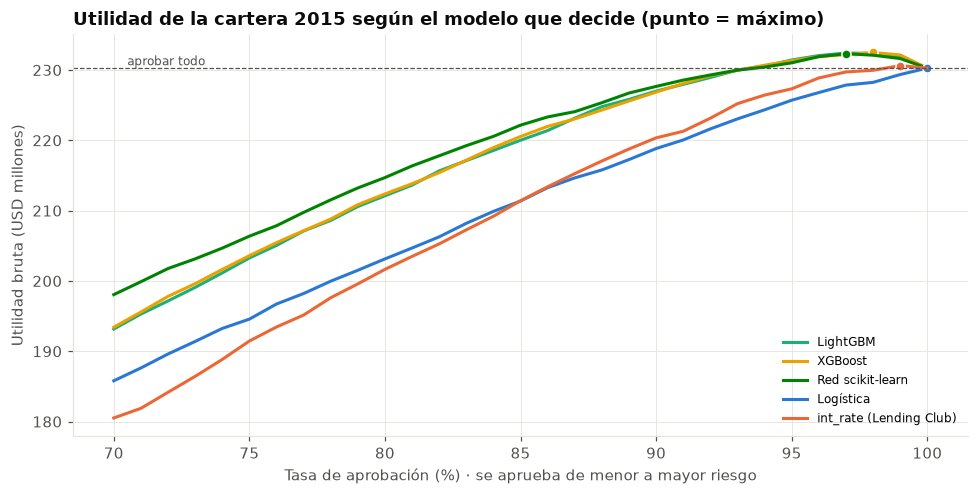

In [9]:
tasas = np.round(np.arange(0.70, 1.0001, 0.01), 2)
curvas = {m: utilidad_por_corte(u, oot["funded_amnt"], s, tasas) for m, s in scores.items()}

fig, ax = plt.subplots(figsize=(9, 4.6))
for m in ["lgbm", "xgb", "mlp", "logistica", "int_rate"]:
    t = curvas[m]
    ax.plot(t.index * 100, t["utilidad"] / 1e6, color=COLOR[m], linewidth=2, label=NOMBRES[m])
    k = t["utilidad"].idxmax()
    ax.plot(k * 100, t.loc[k, "utilidad"] / 1e6, "o", color=COLOR[m], markersize=6, markeredgecolor="white")
ax.axhline(u.sum() / 1e6, color=TINTA_2, linewidth=0.8, linestyle="--")
ax.text(70.5, u.sum() / 1e6 + 0.4, "aprobar todo", fontsize=8, color=TINTA_2)
ax.set_xlabel("Tasa de aprobación (%) · se aprueba de menor a mayor riesgo")
ax.set_ylabel("Utilidad bruta (USD millones)")
ax.set_title("Utilidad de la cartera 2015 según el modelo que decide (punto = máximo)")
ax.legend(frameon=False, loc="lower right", fontsize=8)
fig.tight_layout()

In [10]:
resumen_util = pd.DataFrame({
    NOMBRES[m]: {"aprobación_óptima": curvas[m]["utilidad"].idxmax(),
                 "utilidad_máx_M": curvas[m]["utilidad"].max() / 1e6,
                 "vs_aprobar_todo_M": (curvas[m]["utilidad"].max() - u.sum()) / 1e6,
                 "utilidad_85%_M": curvas[m].loc[0.85, "utilidad"] / 1e6,
                 "roi_85%": curvas[m].loc[0.85, "roi"]}
    for m in scores}).T
resumen_util.sort_values("utilidad_máx_M", ascending=False)

,aprobación_óptima,utilidad_máx_M,vs_aprobar_todo_M,utilidad_85%_M,roi_85%
XGBoost,0.9800,232.5013,2.2319,220.5456,0.0709
LightGBM,0.9700,232.4178,2.1483,220.0164,0.0707
Red scikit-learn,0.9700,232.3180,2.0485,222.1603,0.0707
Random Forest,0.9900,230.8061,0.5366,216.7174,0.0689
int_rate (Lending Club),0.9900,230.6339,0.3645,211.4157,0.0682
Red PyTorch,0.9700,230.6222,0.3528,220.0460,0.0706
Logística,1.0000,230.2694,0.0000,211.3701,0.0672


### Hallazgo: mejor AUC ≠ más utilidad

- **Rechazar por riesgo casi no aumenta la utilidad en 2015:** Lending Club ya cobraba más tasa a los más riesgosos, así que muchos préstamos "malos" de tasa alta igual dejaban ganancia por los intereses cobrados antes de caer.
- **`int_rate` como ranking es el peor en utilidad**, aunque es el benchmark de AUC: rechazar a los de tasa alta es rechazar justo a los que más intereses pagan.
- **La red de scikit-learn gana más dinero que LightGBM en varios cortes** pese a tener menor AUC: el AUC cuenta préstamos, la utilidad cuenta dólares (el monto y la tasa de cada préstamo pesan).

**Implicación:** la decisión correcta de aprobación no es "PD baja", sino **utilidad esperada = f(PD, tasa, monto, severidad)**. Eso es la sesión 7 (política de corte).

## 4. El campeón: LightGBM recalibrado

**Decisión 006 (Neider):** LightGBM, por su rapidez en CPU, que genera menos latencia en producción, y porque captura más malos en el peor decil.
**Decisión 007 (Neider):** recalibrar el campeón con el desplazamiento del intercepto aprendido del 1er semestre de 2015.

> **Pregunta de Neider: si los deciles muestran la mora real, ¿por qué el modelo tiene menos mora que la real?**
> No hay ningún umbral. Las **tablas de eficiencia** solo usan el **orden** de la PD: se ordena, se parte en 10 grupos y en cada uno se cuenta la mora **real**. La **calibración** compara el **valor** de la PD (`predict_proba`, sin umbral) con la mora real. El modelo aprendió con 2012–2014 (13,2% de mora), así que su PD promedio replica ese nivel; en 2015 la mora subió a 14,9% por el contexto, no por los clientes. **El orden está bien; el nivel quedó corto.** La recalibración sube todas las PD sin cambiar su orden.

Código: `src/credit_lab/campeon.py` → `modelos/campeon.joblib`.

In [11]:
from credit_lab.campeon import cargar
campeon = cargar()
s2 = oot[oot["issue_d"].dt.month > 6]
print(f"Desplazamiento del intercepto (logit): {campeon.desplazamiento:.4f}")
pd.DataFrame({"LightGBM sin calibrar": resumen(s2["malo"], campeon.pd_sin_calibrar(s2)),
              "LightGBM recalibrado (campeón)": resumen(s2["malo"], campeon.pd(s2))}).T

Desplazamiento del intercepto (logit): 0.1432


,auc,gini,ks,brier,pd_media,tasa_real
LightGBM sin calibrar,0.6852,0.3704,0.2693,0.1189,0.1289,0.1471
LightGBM recalibrado (campeón),0.6852,0.3704,0.2693,0.1185,0.1449,0.1471


---
## ✍️ Conclusiones de Neider

1. LightGBM y XGBoost le ganan a Lending Club con significancia (IC 95% de la diferencia de AUC sin el cero); entre ellos es un empate. Elijo LightGBM porque corre rápido en CPU, lo que da menos latencia en producción, y captura más malos en el peor decil.
2. Un buen AUC no garantiza una buena PD: el modelo ordena bien, pero subestimó la mora de 2015 en 1,7 puntos porque aprendió con años menos riesgosos. Recalibrar el intercepto con el semestre más reciente la corrige sin tocar el orden.
3. Más AUC no es más plata. Rechazar solo por PD casi no mejora la utilidad, porque los de mayor riesgo también pagan más tasa. La aprobación debe decidirse por utilidad esperada (PD, tasa, monto y pérdida), no solo por PD.